**# Student Performance Analytics — Exploratory Data Analysis

## Objective

Analyze student demographic, academic, social, and behavioral
factors associated with final academic performance.

## Dataset

UCI Student Performance Dataset

## Tools

- Python
- NumPy
- Pandas
- Matplotlib
- Seaborn**

In [1]:
import pandas as pd
import numpy as np
import matplotlib as plt
import seaborn as sns

In [2]:
pd.set_option("display.max_columns", None)

In [3]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print(root)
    for file in files:
        print("  ", file)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/safinulsafin
/kaggle/input/datasets/safinulsafin/studentperformence
   student-mat.csv
   student-por.csv


In [4]:
df_math = pd.read_csv("/kaggle/input/datasets/safinulsafin/studentperformence/student-mat.csv", sep=";")

In [5]:
df_math.head(10)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10
5,GP,M,16,U,LE3,T,4,3,services,other,reputation,mother,1,2,0,no,yes,yes,yes,yes,yes,yes,no,5,4,2,1,2,5,10,15,15,15
6,GP,M,16,U,LE3,T,2,2,other,other,home,mother,1,2,0,no,no,no,no,yes,yes,yes,no,4,4,4,1,1,3,0,12,12,11
7,GP,F,17,U,GT3,A,4,4,other,teacher,home,mother,2,2,0,yes,yes,no,no,yes,yes,no,no,4,1,4,1,1,1,6,6,5,6
8,GP,M,15,U,LE3,A,3,2,services,other,home,mother,1,2,0,no,yes,yes,no,yes,yes,yes,no,4,2,2,1,1,1,0,16,18,19
9,GP,M,15,U,GT3,T,3,4,other,other,home,mother,1,2,0,no,yes,yes,yes,yes,yes,yes,no,5,5,1,1,1,5,0,14,15,15


In [6]:
df_portugese = pd.read_csv("/kaggle/input/datasets/safinulsafin/studentperformence/student-por.csv", sep=";")

In [7]:
df_math.info()
df_portugese.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [8]:
df_math.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [9]:
print(df_math.shape)
print(df_math.columns.tolist())

(395, 33)
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


In [10]:
df_math.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

In [11]:
df_math.duplicated().sum()
df_portugese.duplicated().sum()

np.int64(0)

In [12]:
df_portugese.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

In [13]:
# Duplicate rows
df_math.duplicated().sum()
df_portugese.duplicated().sum()
df_math.dtypes
df_portugese.dtypes
df_math.describe()
df_portugese.describe()
df_math["school"].value_counts()
df_math["sex"].value_counts()
df_math["address"].value_counts()
df_math["famsize"].value_counts()
df_math["Mjob"].value_counts()
df_math["Fjob"].value_counts()

df_portugese["school"].value_counts()
df_portugese["sex"].value_counts()
df_portugese["address"].value_counts()
df_portugese["famsize"].value_counts()
df_portugese["Mjob"].value_counts()
df_portugese["Fjob"].value_counts()
df_math[["age", "traveltime", "studytime", "failures",
    "famrel", "freetime", "goout", "Dalc", "Walc",
    "health", "absences", "G1", "G2", "G3"]].describe()
df_portugese[["age", "traveltime", "studytime", "failures",
    "famrel", "freetime", "goout", "Dalc", "Walc",
    "health", "absences", "G1", "G2", "G3"]].describe()

,age,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


In [14]:
df_portugese.duplicated().sum()

np.int64(0)

In [15]:
categorical_cols = [
    "school",
    "sex",
    "address",
    "famsize",
    "Pstatus",
    "Mjob",
    "Fjob",
    "reason",
    "guardian",
    "schoolsup",
    "famsup",
    "paid",
    "activities",
    "nursery",
    "higher",
    "internet",
    "romantic"
]

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df_portugese[col].value_counts())


--- school ---
school
GP    423
MS    226
Name: count, dtype: int64

--- sex ---
sex
F    383
M    266
Name: count, dtype: int64

--- address ---
address
U    452
R    197
Name: count, dtype: int64

--- famsize ---
famsize
GT3    457
LE3    192
Name: count, dtype: int64

--- Pstatus ---
Pstatus
T    569
A     80
Name: count, dtype: int64

--- Mjob ---
Mjob
other       258
services    136
at_home     135
teacher      72
health       48
Name: count, dtype: int64

--- Fjob ---
Fjob
other       367
services    181
at_home      42
teacher      36
health       23
Name: count, dtype: int64

--- reason ---
reason
course        285
home          149
reputation    143
other          72
Name: count, dtype: int64

--- guardian ---
guardian
mother    455
father    153
other      41
Name: count, dtype: int64

--- schoolsup ---
schoolsup
no     581
yes     68
Name: count, dtype: int64

--- famsup ---
famsup
yes    398
no     251
Name: count, dtype: int64

--- paid ---
paid
no     610
yes     39
Name

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

print(plt)
print(plt.figure)

<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>
<function figure at 0x7c3673bf3060>


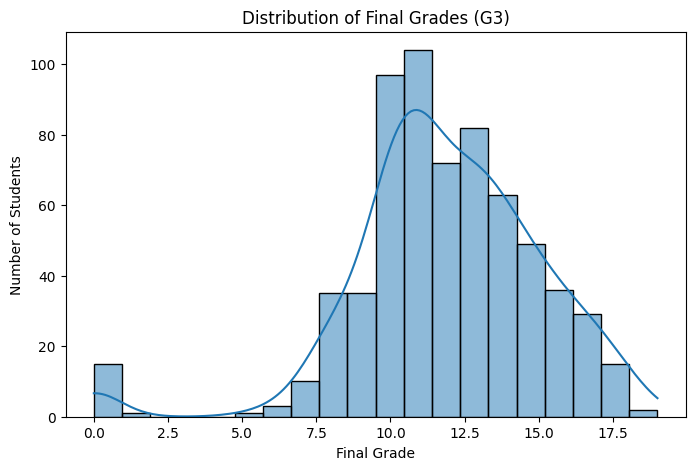

In [17]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_portugese,
    x="G3",
    bins=20,
    kde=True
)

plt.title("Distribution of Final Grades (G3)")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")

plt.show()

**Observation: The distribution of final grades (G3) is concentrated around the middle of the grading scale, with a large proportion of students scoring approximately between 10 and 12.**

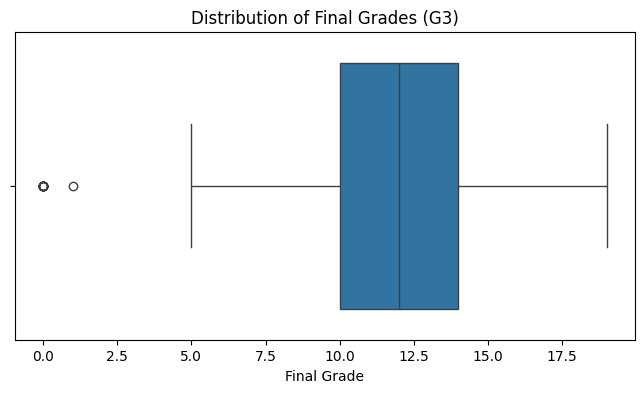

In [18]:
plt.figure(figsize=(8, 4))

sns.boxplot(
    data=df_portugese,
    x="G3"
)

plt.title("Distribution of Final Grades (G3)")
plt.xlabel("Final Grade")

plt.show()

**### Observations

- Most students' final grades are concentrated around 10–12.
- The distribution is centered around the median grade of 12.
- Students' final grades show noticeable variation, ranging from 0 to 19.**

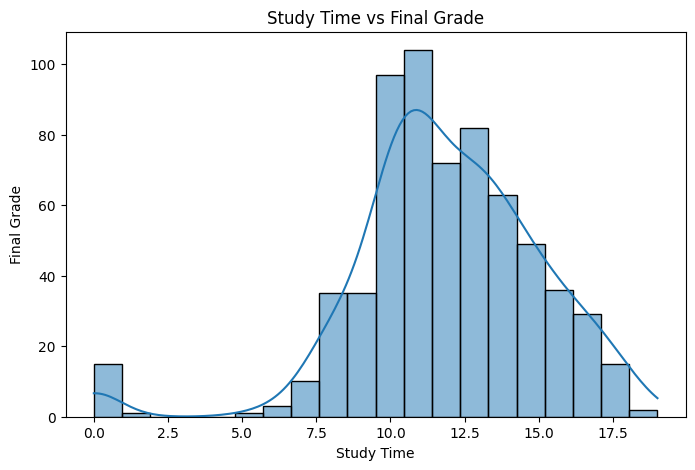

In [19]:
plt.figure(figsize=(8,5))

sns.histplot(data=df_portugese,
    x="G3",
    bins=20,
    kde=True)

plt.title("Study Time vs Final Grade")
plt.xlabel("Study Time")
plt.ylabel("Final Grade")

plt.show()

In [20]:
df_portugese.groupby("studytime")["G3"].agg(
    ["count", "mean", "median", "std"]
).round(2)

,count,mean,median,std
studytime,,,,
1,212,10.84,11.0,3.22
2,305,12.09,12.0,3.24
3,97,13.23,13.0,2.50
4,35,13.06,13.0,3.04


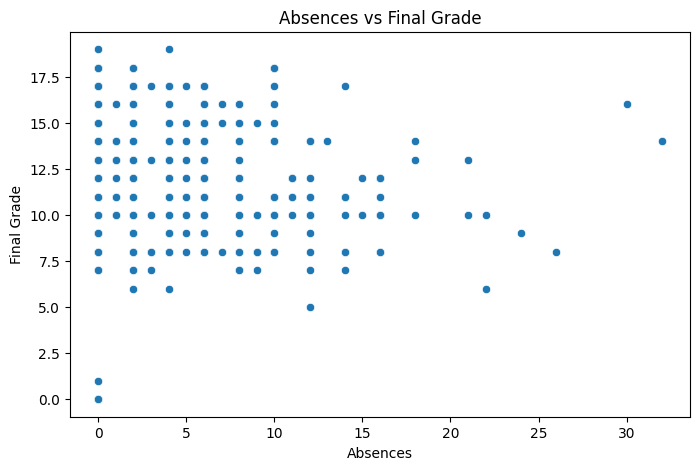

In [21]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df_portugese,
    x="absences",
    y="G3"
)

plt.title("Absences vs Final Grade")
plt.xlabel("Absences")
plt.ylabel("Final Grade")

plt.show()

In [22]:
df_portugese[["absences", "G3"]].corr()

,absences,G3
absences,1.000000,-0.091379
G3,-0.091379,1.000000


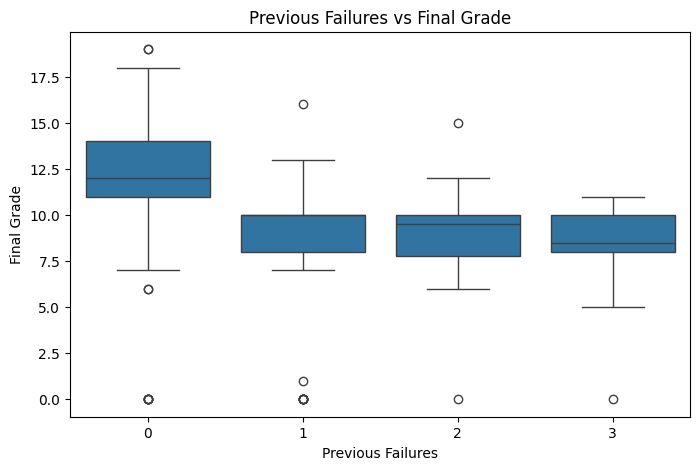

In [23]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df_portugese,
    x="failures",
    y="G3"
)

plt.title("Previous Failures vs Final Grade")
plt.xlabel("Previous Failures")
plt.ylabel("Final Grade")

plt.show()

In [24]:
df_portugese.groupby("failures")["G3"].agg(
    ["count", "mean", "median", "std"]
).round(2)

,count,mean,median,std
failures,,,,
0,549,12.51,12.0,2.83
1,70,8.64,10.0,3.44
2,16,8.81,9.5,3.21
3,14,8.07,8.5,2.79


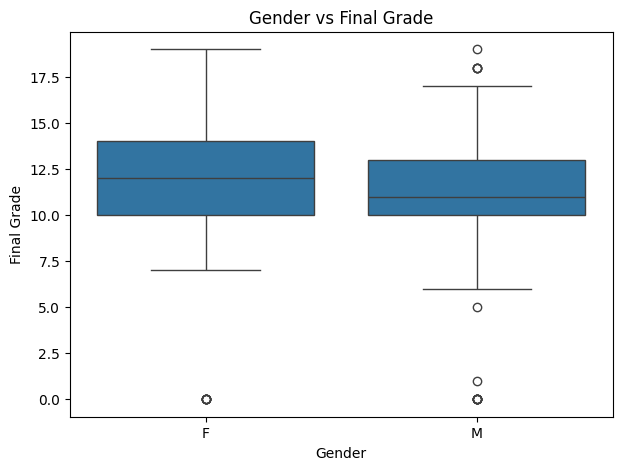

In [25]:
plt.figure(figsize=(7,5))

sns.boxplot(
    data=df_portugese,
    x="sex",
    y="G3"
)

plt.title("Gender vs Final Grade")
plt.xlabel("Gender")
plt.ylabel("Final Grade")

plt.show()

In [26]:
df_portugese.groupby("sex")["G3"].agg(
    ["count", "mean", "median"]
).round(2)

,count,mean,median
sex,,,
F,383,12.25,12.0
M,266,11.41,11.0


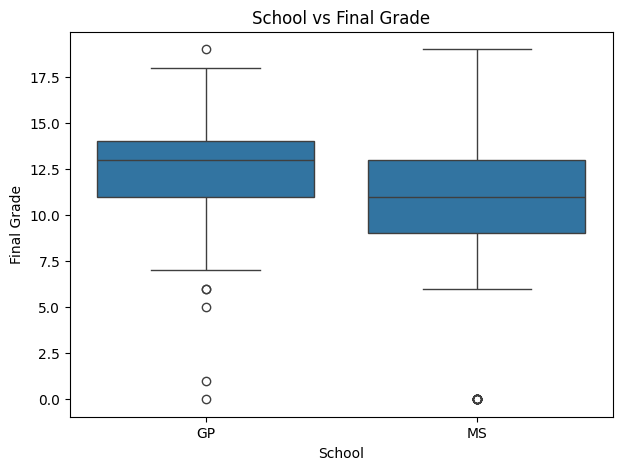

In [27]:
plt.figure(figsize=(7,5))

sns.boxplot(
    data=df_portugese,
    x="school",
    y="G3"
)

plt.title("School vs Final Grade")
plt.xlabel("School")
plt.ylabel("Final Grade")

plt.show()

In [28]:
df_portugese.groupby("school")["G3"].agg(
    ["count", "mean", "median"]
).round(2)

,count,mean,median
school,,,
GP,423,12.58,13.0
MS,226,10.65,11.0


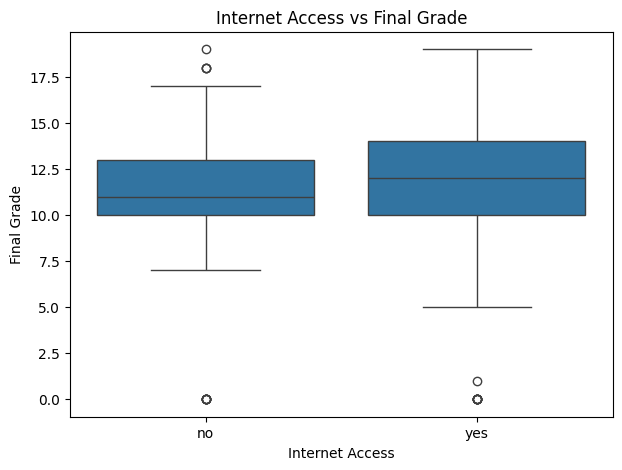

In [29]:
plt.figure(figsize=(7,5))

sns.boxplot(
    data=df_portugese,
    x="internet",
    y="G3"
)

plt.title("Internet Access vs Final Grade")
plt.xlabel("Internet Access")
plt.ylabel("Final Grade")

plt.show()

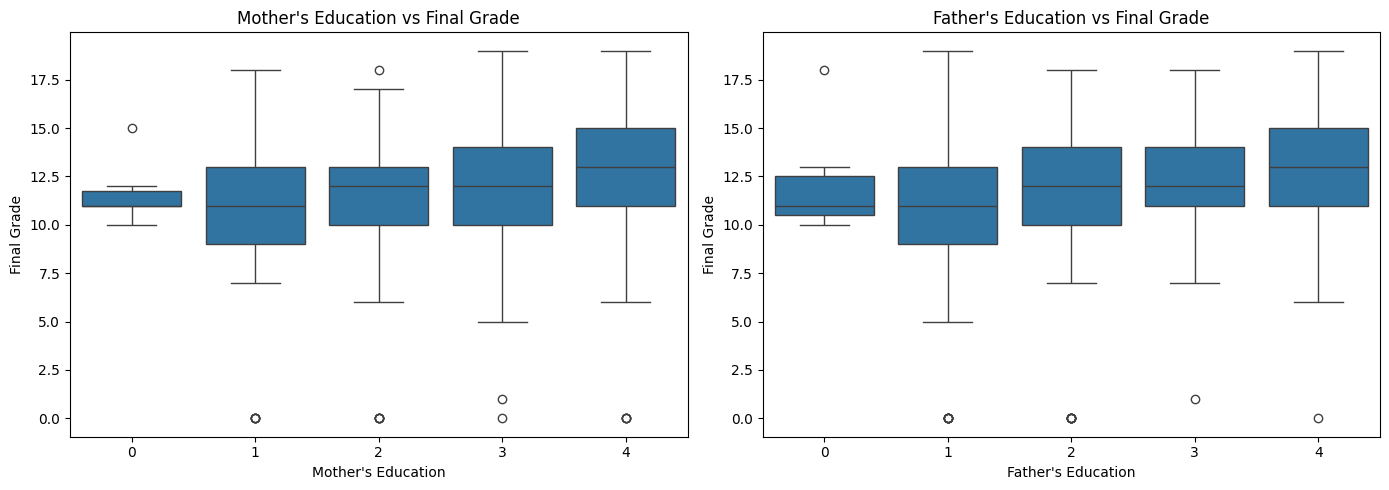

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

sns.boxplot(data=df_portugese, x="Medu", y="G3", ax=axes[0])
axes[0].set_title("Mother's Education vs Final Grade")
axes[0].set_xlabel("Mother's Education")
axes[0].set_ylabel("Final Grade")

sns.boxplot(data=df_portugese, x="Fedu", y="G3", ax=axes[1])
axes[1].set_title("Father's Education vs Final Grade")
axes[1].set_xlabel("Father's Education")
axes[1].set_ylabel("Final Grade")

plt.tight_layout()
plt.show()

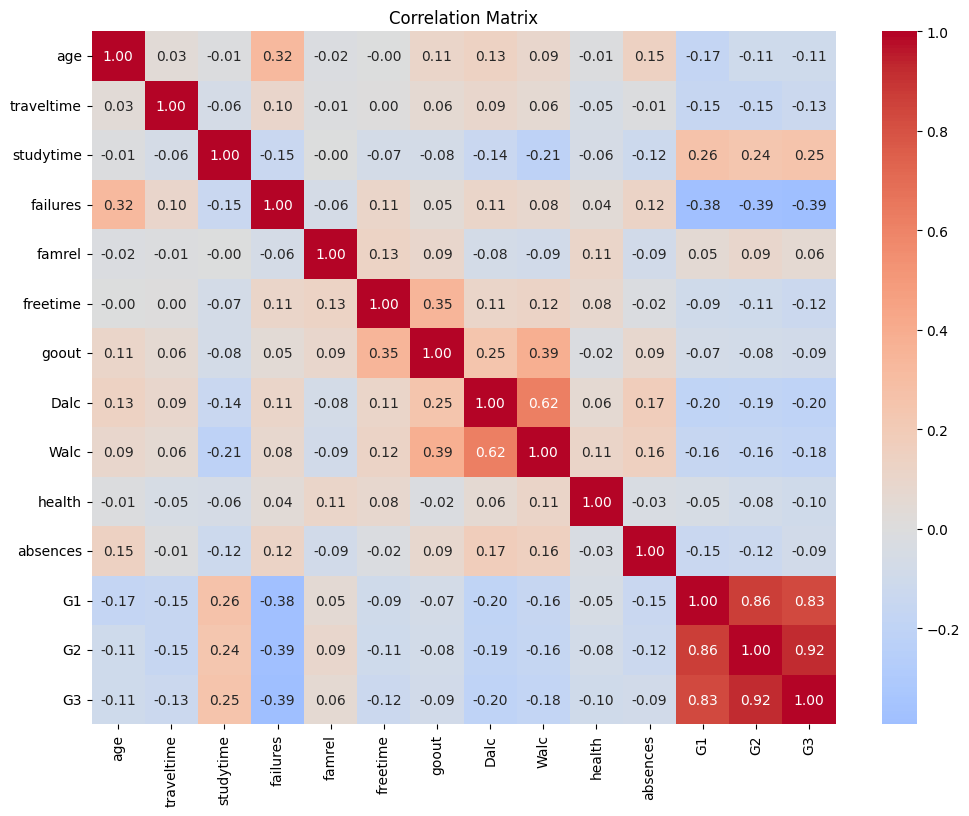

In [31]:
numeric_cols = [
    "age",
    "traveltime",
    "studytime",
    "failures",
    "famrel",
    "freetime",
    "goout",
    "Dalc",
    "Walc",
    "health",
    "absences",
    "G1",
    "G2",
    "G3"
]

corr = df_portugese[numeric_cols].corr()

plt.figure(figsize=(12,9))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix")
plt.show()

In [32]:
corr["G3"].sort_values(ascending=False)

G3            1.000000
G2            0.918548
G1            0.826387
studytime     0.249789
famrel        0.063361
goout        -0.087641
absences     -0.091379
health       -0.098851
age          -0.106505
freetime     -0.122705
traveltime   -0.127173
Walc         -0.176619
Dalc         -0.204719
failures     -0.393316
Name: G3, dtype: float64

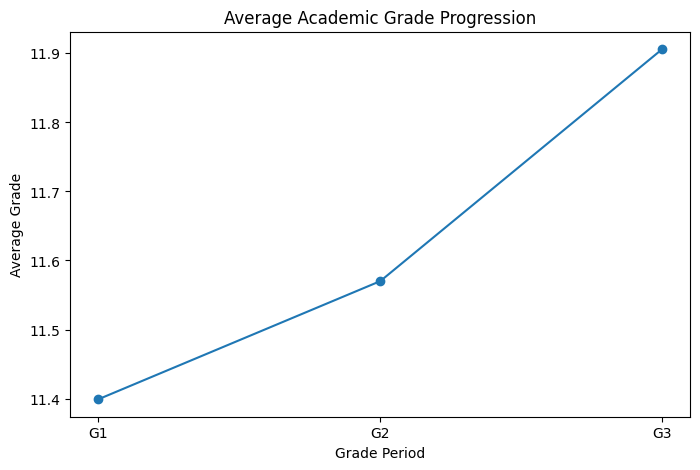

In [33]:
grade_means = df_portugese[["G1", "G2", "G3"]].mean()

plt.figure(figsize=(8,5))

plt.plot(
    grade_means.index,
    grade_means.values,
    marker="o"
)

plt.title("Average Academic Grade Progression")
plt.xlabel("Grade Period")
plt.ylabel("Average Grade")

plt.show()

**Study time has a positive correlation with final grade (G3), with a Pearson correlation coefficient of approximately 0.25. This suggests that students reporting higher study time tend to have higher final grades, although the relationship is relatively weak to moderate.Previous failures show a stronger negative association with G3 (r ≈ −0.39), suggesting that students with more previous failures tend to have lower final grades.**

In [34]:
df_portugese.groupby("studytime")["G3"].agg(
    ["count", "mean", "median", "std"]
).round(2)

,count,mean,median,std
studytime,,,,
1,212,10.84,11.0,3.22
2,305,12.09,12.0,3.24
3,97,13.23,13.0,2.50
4,35,13.06,13.0,3.04


### Observation

Students with higher study time generally achieved higher final grades.
The average G3 increased from 10.84 for studytime 1 to 13.23 for studytime 3.
However, studytime 4 had a slightly lower mean grade (13.06), suggesting
that the relationship is positive but not perfectly linear.

Studytime 3 also had a smaller sample size (97 students), while studytime 4
had only 35 students, so the results for these groups should be interpreted
with some caution.

In [35]:
df_portugese.groupby("failures")["G3"].agg(
    ["count", "mean", "median", "std"]
).round(2)

,count,mean,median,std
failures,,,,
0,549,12.51,12.0,2.83
1,70,8.64,10.0,3.44
2,16,8.81,9.5,3.21
3,14,8.07,8.5,2.79


**### Observation

Students with no previous failures had a substantially higher average final
grade (12.51) compared with students who had previous failures, whose average
grades were approximately 8–9.

The negative correlation between failures and G3 (-0.393) also indicates a
moderate negative association. However, this is an observational relationship
and should not be interpreted as evidence that previous failures directly
cause lower final grades.

The groups with two or three previous failures are relatively small, so their
results should be interpreted cautiously.**

In [36]:
df_portugese.groupby("sex")["G3"].agg(
    ["count", "mean", "median", "std"]
).round(2)

,count,mean,median,std
sex,,,,
F,383,12.25,12.0,3.12
M,266,11.41,11.0,3.32


**### Observation

Female students had a somewhat higher average final grade than male students
in this dataset (12.25 vs 11.41). The median grade was also slightly higher
for female students (12 vs 11).

This represents an observed difference in this dataset and should not be
interpreted as evidence that gender causes differences in academic performance.**

In [37]:
df_portugese.groupby("school")["G3"].agg(
    ["count", "mean", "median", "std"]
).round(2)

,count,mean,median,std
school,,,,
GP,423,12.58,13.0,2.63
MS,226,10.65,11.0,3.83


**### Observation

Students from GP had a higher average final grade than students from MS
(12.58 vs 10.65). The median was also higher for GP students (13 vs 11).

This difference indicates an association between school and final grade in
this dataset. However, it does not imply that attending a particular school
causes higher or lower academic performance, since other student and family
characteristics may also contribute to the observed difference.**

In [38]:
df_portugese.groupby("internet")["G3"].agg(
    ["count", "mean", "median", "std"]
).round(2)

,count,mean,median,std
internet,,,,
no,151,11.03,11.0,3.45
yes,498,12.17,12.0,3.12


**### Observation

Students with internet access had a higher average final grade than students
without internet access (12.17 vs 11.03). The median grade was also slightly
higher for students with internet access (12 vs 11).

This indicates an association between internet access and academic performance
in this dataset, but it does not establish a causal relationship.**

In [39]:
df_portugese.groupby("Medu")["G3"].agg(
    ["count", "mean", "median", "std"]
).round(2)

,count,mean,median,std
Medu,,,,
0,6,11.67,11.0,1.75
1,143,10.80,11.0,3.16
2,186,11.66,12.0,3.06
3,139,11.92,12.0,3.12
4,175,13.07,13.0,3.24


**### Observation

Final grades generally tend to be higher among students whose mothers
have higher levels of education. The highest maternal education category
(Medu = 4) has the highest average final grade (13.07).

However, the relationship is not perfectly linear across all categories.
The Medu = 0 group contains only 6 students, so its result should be
interpreted cautiously.**

In [40]:
df_portugese.groupby("Fedu")["G3"].agg(
    ["count", "mean", "median", "std"]
).round(2)

,count,mean,median,std
Fedu,,,,
0,7,12.14,11.0,2.79
1,174,10.94,11.0,3.42
2,209,11.78,12.0,3.45
3,131,12.38,12.0,2.49
4,128,12.92,13.0,2.92


**### Observation

Students with higher levels of father's education generally had higher
average final grades. The mean G3 increased from 10.94 for Fedu = 1
to 12.92 for Fedu = 4.

The Fedu = 0 category contains only 7 students, so its relatively high
mean should be interpreted cautiously.

This finding represents an association rather than a causal relationship.**

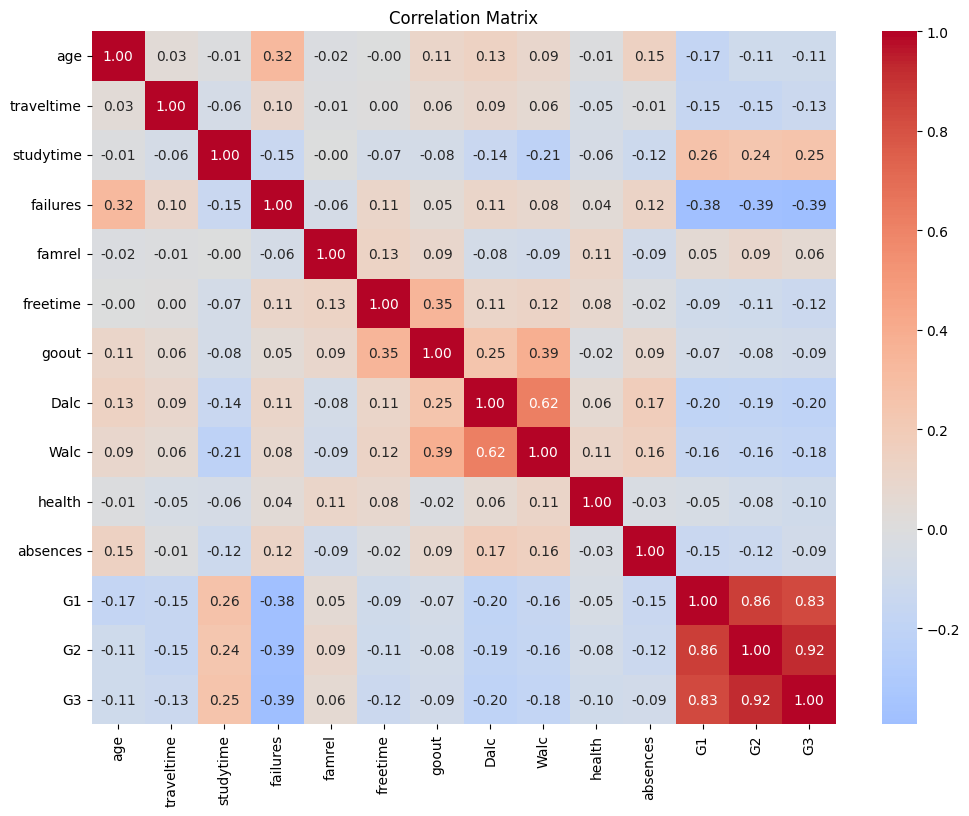

In [41]:
numeric_cols = [
    "age",
    "traveltime",
    "studytime",
    "failures",
    "famrel",
    "freetime",
    "goout",
    "Dalc",
    "Walc",
    "health",
    "absences",
    "G1",
    "G2",
    "G3"
]

corr = df_portugese[numeric_cols].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix")
plt.show()

In [42]:
corr["G3"].sort_values(ascending=False)

G3            1.000000
G2            0.918548
G1            0.826387
studytime     0.249789
famrel        0.063361
goout        -0.087641
absences     -0.091379
health       -0.098851
age          -0.106505
freetime     -0.122705
traveltime   -0.127173
Walc         -0.176619
Dalc         -0.204719
failures     -0.393316
Name: G3, dtype: float64

**## Correlation Analysis

The correlation analysis shows that G2 has the strongest positive
relationship with final grade G3 (r = 0.919), followed by G1
(r = 0.826).

Among the behavioral and background variables, studytime has a positive
association with G3 (r = 0.250), while previous failures show a stronger
negative association (r = -0.393).

Alcohol consumption also shows negative associations with final grade,
with Dalc (workday alcohol consumption) at -0.205 and Walc (weekend
alcohol consumption) at -0.177.

These correlations represent associations and should not be interpreted
as causal relationships.**

**## Target Leakage Consideration

G1 and G2 have very strong correlations with G3 because they represent
earlier academic grades.

Their usefulness depends on the intended prediction timing. If the goal
is to predict final performance after G1 and G2 become available, these
variables may be valid predictors.

However, if the goal is to predict final performance before these grades
are available, G1 and G2 should be excluded from the predictive model.**

In [43]:
grade_means = df_portugese[["G1", "G2", "G3"]].mean()

grade_means

G1    11.399076
G2    11.570108
G3    11.906009
dtype: float64

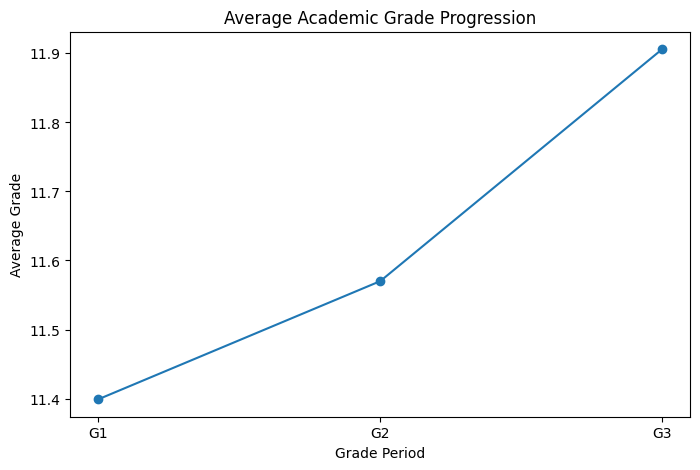

In [44]:
plt.figure(figsize=(8, 5))

plt.plot(
    grade_means.index,
    grade_means.values,
    marker="o"
)

plt.title("Average Academic Grade Progression")
plt.xlabel("Grade Period")
plt.ylabel("Average Grade")

plt.show()

**## Academic Grade Progression

The average academic grade shows a gradual increase across the three
assessment periods:

- G1: 11.40
- G2: 11.57
- G3: 11.91

Overall, the average grade increases from the first assessment to the
final grade. This is consistent with the strong positive correlations
observed between G1, G2, and G3.**

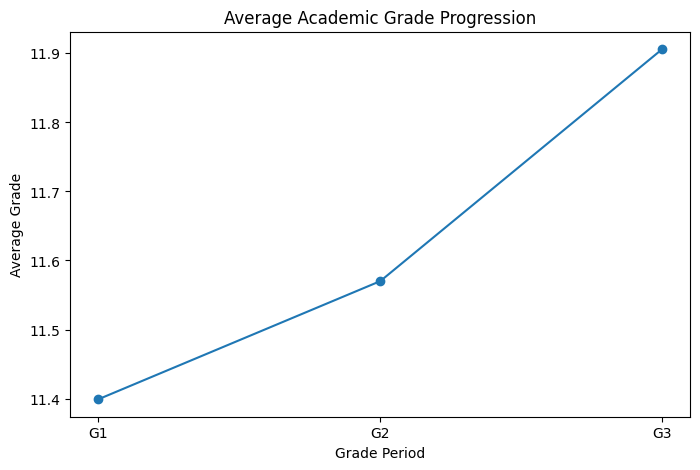

In [45]:
grade_means = df_portugese[["G1", "G2", "G3"]].mean()

plt.figure(figsize=(8, 5))

plt.plot(
    grade_means.index,
    grade_means.values,
    marker="o"
)

plt.title("Average Academic Grade Progression")
plt.xlabel("Grade Period")
plt.ylabel("Average Grade")

plt.show()

In [46]:
df_portugese["parent_education_avg"] = (
    df_portugese["Medu"] + df_portugese["Fedu"]
) / 2

df_portugese["alcohol_consumption"] = (
    df_portugese["Dalc"] + df_portugese["Walc"]
)

In [47]:
df_portugese[
    ["Medu", "Fedu", "parent_education_avg",
     "Dalc", "Walc", "alcohol_consumption"]
].head()

,Medu,Fedu,parent_education_avg,Dalc,Walc,alcohol_consumption
0,4,4,4.0,1,1,2
1,1,1,1.0,1,1,2
2,1,1,1.0,2,3,5
3,4,2,3.0,1,1,2
4,3,3,3.0,1,2,3


**## Key Findings

1. Final grades are generally concentrated around the middle of the
   grading range, with an average G3 of approximately 11.91.

2. Study time shows a positive association with final grade. Students
   in higher study-time categories generally have higher average grades.

3. Previous failures show a relatively strong negative association with
   final grade. Students with no previous failures have a substantially
   higher average G3.

4. Female students have a somewhat higher average final grade than male
   students in this dataset.

5. GP students have a higher average final grade than MS students.

6. Students with internet access have a higher average final grade than
   students without internet access.

7. Higher parental education levels are generally associated with higher
   average final grades.

8. G1 and G2 have the strongest correlations with G3, but their use in
   predictive modeling depends on when the prediction is intended to be
   made.**

**## Limitations

- The dataset represents students from Portuguese schools and may not
  generalize to other countries or educational systems.

- The analysis identifies associations and does not establish causation.

- Several variables are self-reported and may contain reporting bias.

- Some categorical groups contain relatively few observations.

- G1 and G2 are strongly related to G3 because they represent earlier
  academic grades. Their use as predictors may create a target-timing
  problem depending on the prediction scenario.

- The dataset is relatively small, so findings should be interpreted
  cautiously when generalizing to larger populations.**

**## Conclusion

This exploratory data analysis examined academic performance and several
student, family, behavioral, and educational factors using the Portuguese
student performance dataset.

The analysis found that previous failures and study time are among the
notable behavioral/academic factors associated with final performance.
Parental education, school, gender, and internet access also showed
differences in average final grades.

The strongest relationships with G3 were observed for G1 and G2. However,
these variables represent earlier grades and therefore require careful
consideration when designing a predictive model.

Overall, the EDA provides useful insights into patterns in student
performance and establishes a foundation for future statistical analysis
or machine learning modeling.**